<a href="https://colab.research.google.com/github/manchinillaanvesh257-bot/.py/blob/main/Copy_of_Untitled3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Sample CSV dataset created successfully!

--- Original Dataset ---
      Name   Age  Gender  Python_Score  Statistics_Score  Attendance
0   Anvesh  21.0    Male            85                80          95
1    Rahul  22.0    Male            78                75          88
2    Priya  20.0  Female            92                90          98
3    Sneha  21.0  Female            88                85          90
4    Kiran  23.0    Male            67                65          75
5    Arjun  22.0    Male            75                70          80
6   Ananya  20.0  Female            95                93          99
7    Rahul  22.0    Male            78                75          88
8    Vijay  24.0    Male            60                58          65
9    Divya   NaN  Female            89                87          92
10   Kiran  23.0    Male            67                65          75

--- Dataset Dimensions ---
Number of rows: 11
Number of columns: 6

--- Dataset Information ---
<class '

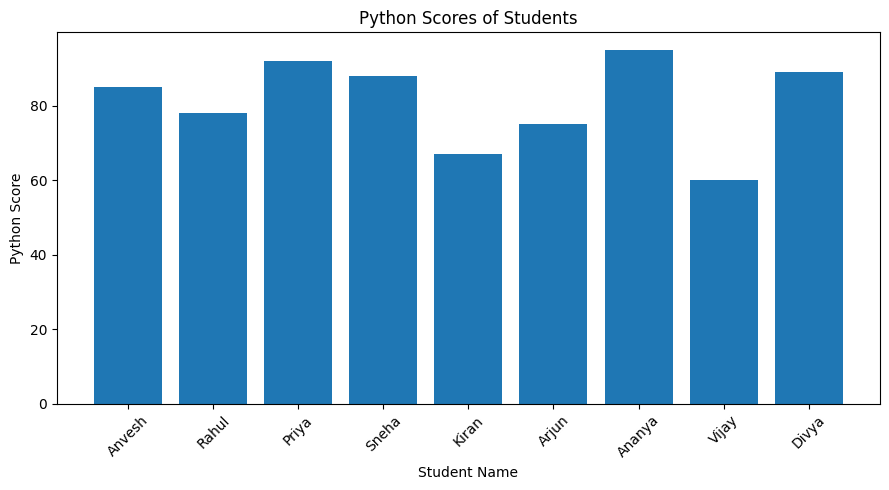

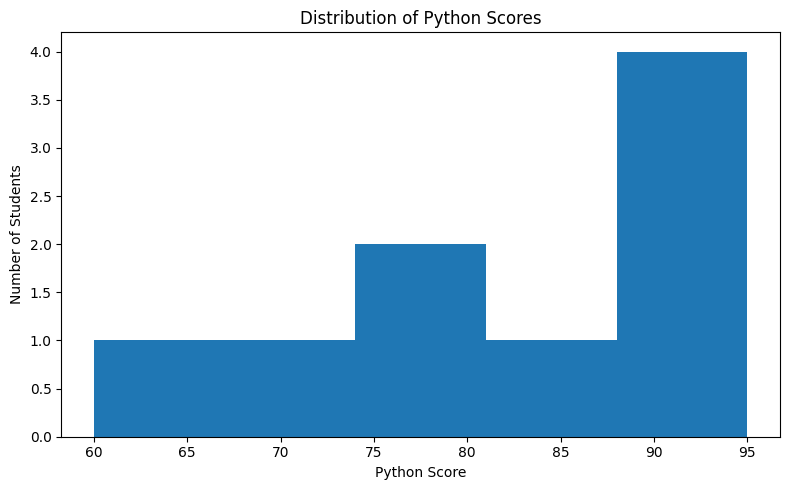

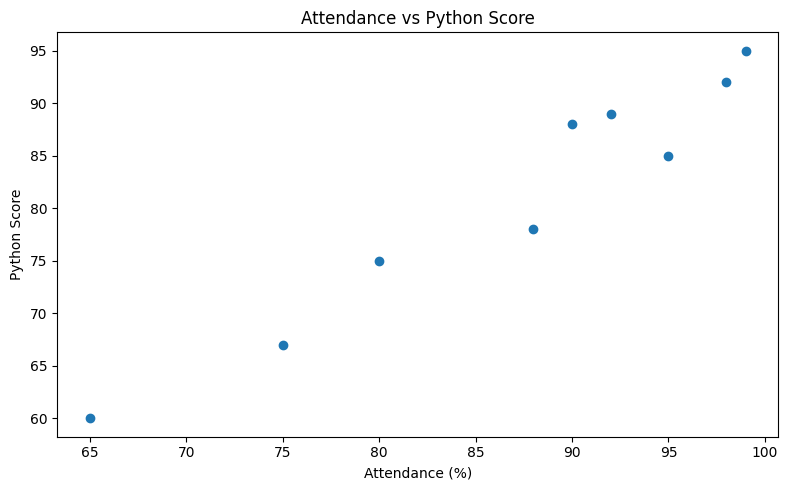


DATA ANALYSIS COMPLETED!
Cleaned dataset saved successfully.
Generated visualizations:
1. python_scores_bar_chart.png
2. python_scores_histogram.png
3. attendance_vs_python.png


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# STEP 1: CREATE A SAMPLE CSV DATASET

data = {
    "Name": [
        "Anvesh", "Rahul", "Priya", "Sneha",
        "Kiran", "Arjun", "Ananya", "Rahul",
        "Vijay", "Divya", "Kiran"
    ],
    "Age": [
        21, 22, 20, 21, 23, 22, 20, 22, 24, np.nan, 23
    ],
    "Gender": [
        "Male", "Male", "Female", "Female",
        "Male", "Male", "Female", "Male",
        "Male", "Female", "Male"
    ],
    "Python_Score": [
        85, 78, 92, 88, 67, 75, 95, 78, 60, 89, 67
    ],
    "Statistics_Score": [
        80, 75, 90, 85, 65, 70, 93, 75, 58, 87, 65
    ],
    "Attendance": [
        95, 88, 98, 90, 75, 80, 99, 88, 65, 92, 75
    ]
}

df_sample = pd.DataFrame(data)

# Save the dataset as a CSV file
df_sample.to_csv("student_performance.csv", index=False)

print("Sample CSV dataset created successfully!")


# ==========================================
# STEP 2: LOAD THE CSV DATASET
# ==========================================

df = pd.read_csv("student_performance.csv")

print("\n--- Original Dataset ---")
print(df)


# ==========================================
# STEP 3: IDENTIFY ROWS AND COLUMNS
# ==========================================

print("\n--- Dataset Dimensions ---")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


# ==========================================
# STEP 4: ANALYZE DATA STRUCTURE
# ==========================================

print("\n--- Dataset Information ---")
df.info()

print("\n--- Column Data Types ---")
print(df.dtypes)


# ==========================================
# STEP 5: CHECK MISSING VALUES
# ==========================================

print("\n--- Missing Values ---")
print(df.isnull().sum())


# ==========================================
# STEP 6: IDENTIFY DUPLICATE RECORDS
# ==========================================

print("\n--- Number of Duplicate Rows ---")
print(df.duplicated().sum())

print("\n--- Duplicate Records ---")
print(df[df.duplicated()])


# ==========================================
# STEP 7: REMOVE DUPLICATES
# ==========================================

df = df.drop_duplicates()

print("\nDataset after removing duplicates:")
print(df)

print("Rows after duplicate removal:", len(df))


# ==========================================
# STEP 8: BASIC DATA CLEANING
# ==========================================

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Remove extra spaces from text values
df["Name"] = df["Name"].str.strip()
df["Gender"] = df["Gender"].str.strip()

# Convert numerical columns to numeric data types
numeric_columns = [
    "Age", "Python_Score",
    "Statistics_Score", "Attendance"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Fill missing age values with the median age
df["Age"] = df["Age"].fillna(df["Age"].median())

# Validate score and attendance ranges
for col in ["Python_Score", "Statistics_Score", "Attendance"]:
    df.loc[~df[col].between(0, 100), col] = np.nan

print("\n--- Cleaned Dataset ---")
print(df)

print("\n--- Missing Values After Cleaning ---")
print(df.isnull().sum())


# ==========================================
# STEP 9: STATISTICAL ANALYSIS
# ==========================================

print("\n--- Statistical Summary ---")
print(df.describe())

print("\n--- Average Python Score ---")
print(df["Python_Score"].mean())

print("\n--- Average Statistics Score ---")
print(df["Statistics_Score"].mean())

print("\n--- Average Attendance ---")
print(df["Attendance"].mean())

print("\n--- Highest Python Score ---")
print(df["Python_Score"].max())

print("\n--- Lowest Python Score ---")
print(df["Python_Score"].min())


# ==========================================
# STEP 10: CREATE AVERAGE SCORE COLUMN
# ==========================================

df["Average_Score"] = df[
    ["Python_Score", "Statistics_Score"]
].mean(axis=1)

print("\n--- Student Average Scores ---")
print(df[["Name", "Average_Score"]])


# ==========================================
# VISUALIZATION 1: BAR CHART
# ==========================================

plt.figure(figsize=(9, 5))

plt.bar(df["Name"], df["Python_Score"])

plt.title("Python Scores of Students")
plt.xlabel("Student Name")
plt.ylabel("Python Score")
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig("python_scores_bar_chart.png")
plt.show()


# ==========================================
# VISUALIZATION 2: HISTOGRAM
# ==========================================

plt.figure(figsize=(8, 5))

plt.hist(df["Python_Score"].dropna(), bins=5)

plt.title("Distribution of Python Scores")
plt.xlabel("Python Score")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.savefig("python_scores_histogram.png")
plt.show()


# ==========================================
# VISUALIZATION 3: SCATTER PLOT
# ==========================================

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Attendance"],
    df["Python_Score"]
)

plt.title("Attendance vs Python Score")
plt.xlabel("Attendance (%)")
plt.ylabel("Python Score")

plt.tight_layout()
plt.savefig("attendance_vs_python.png")
plt.show()


# ==========================================
# STEP 11: SAVE THE CLEANED DATASET
# ==========================================

df.to_csv("cleaned_student_performance.csv", index=False)

print("\n================================")
print("DATA ANALYSIS COMPLETED!")
print("================================")
print("Cleaned dataset saved successfully.")
print("Generated visualizations:")
print("1. python_scores_bar_chart.png")
print("2. python_scores_histogram.png")
print("3. attendance_vs_python.png")